# 密度与浓相边界

本 Notebook 仅读取上游数值结果，不重新估计边界。横轴是相对盒中心的 z 位置。
密度由全部残基珠分箱、除以每链珠数后换算为链当量浓度，再对帧等权平均。
虚线为中心峰高的一半；右侧首次低于该高度的箱中心给出半宽 w，浓相核心取 ±0.6w。
左侧半高位置仅作对称性诊断，不参与当前边界定义。边界无效时计算阶段明确报错，不使用固定宽度。


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project among the working directory and its parents.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "simulations.yaml").is_file()), None
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the project, or set ROOT explicitly")
sys.path.insert(0, str(ROOT))
from common import inputs
from common import results as files

CONFIG = ROOT / "simulations.yaml"
SELECTED = None  # None means all registered simulations.
RESULTS_ROOT = ROOT / "03_results"
SIMULATIONS = inputs.select_simulations(CONFIG, SELECTED)
RESULTS = {s["id"]: files.completed(RESULTS_ROOT / s["id"] / "01_basic/phase_boundary") for s in SIMULATIONS}
SOURCES = {key: files.read_json(path / "metadata.json") for key, path in RESULTS.items()}
COLORS = {name: plt.get_cmap("tab10")(i % 10) for i, name in enumerate(RESULTS)}
FIGURES = ROOT / "05_plot/01_basic/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    }
)


def export(fig, name):
    for key, path in RESULTS.items():
        files.completed(path)
        if files.read_json(path / "metadata.json") != SOURCES[key]:
            raise ValueError("Results changed; restart and rerun the notebook")
    for extension in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"{name}.{extension}", dpi=300, bbox_inches="tight")
    files.write_json(
        FIGURES / f"{name}.sources.json",
        {key: files.read_json(path / "metadata.json") for key, path in RESULTS.items()},
    )


,simulation_id,method,peak_chain_mM,half_height_chain_mM,right_half_height_z_nm,left_half_height_z_nm,half_width_asymmetry_nm,dense_coefficient,dense_half_width_nm,left_crossing_found,fixed_width_fallback,n_frames,box_nm,bin_width_nm,peak_halfwidth_bins
0,A18_T260,central_peak_half_height_right_first_bin,16.560229,8.280114,18.75,-18.95,-0.2,0.6,11.25,True,False,750,"[15.0, 15.0, 150.0]",0.1,5
1,B01_T260,central_peak_half_height_right_first_bin,23.978127,11.989063,14.85,-14.95,-0.1,0.6,8.91,True,False,750,"[15.0, 15.0, 150.0]",0.1,5
2,B10_T260,central_peak_half_height_right_first_bin,17.838627,8.919313,16.35,-16.15,0.2,0.6,9.81,True,False,750,"[15.0, 15.0, 150.0]",0.1,5


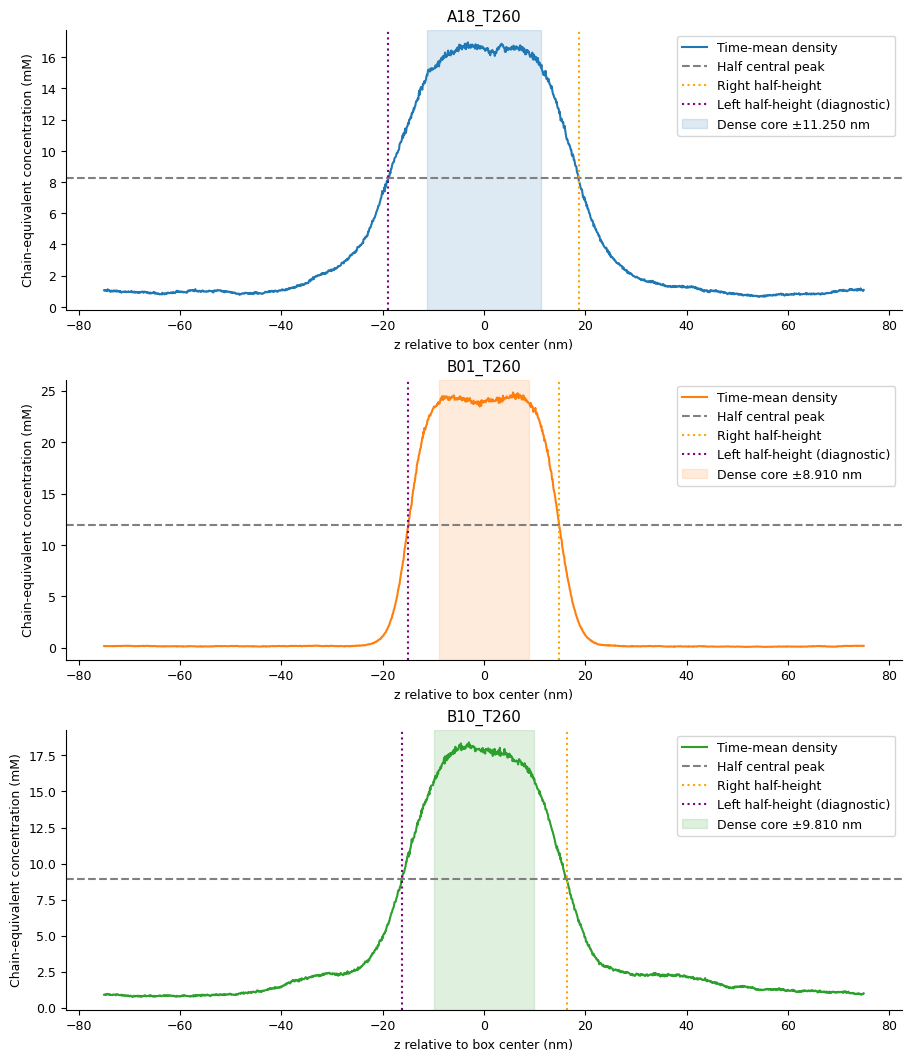

In [2]:
fig, axes = plt.subplots(
    len(RESULTS), 1, figsize=(9, 3.5 * len(RESULTS)), squeeze=False, constrained_layout=True
)
records = []
for ax, (name, path) in zip(axes[:, 0], RESULTS.items()):
    data = pd.read_csv(path / "density_profile.csv")
    boundary = files.read_json(path / "boundary.json")
    records.append({"simulation_id": name, **boundary})
    ax.plot(data.z_nm, data.mean_chain_mM, color=COLORS[name], label="Time-mean density")
    ax.axhline(boundary["half_height_chain_mM"], color="gray", ls="--", label="Half central peak")
    ax.axvline(
        boundary["right_half_height_z_nm"], color="orange", ls=":", label="Right half-height"
    )
    if boundary["left_crossing_found"]:
        ax.axvline(
            boundary["left_half_height_z_nm"],
            color="purple",
            ls=":",
            label="Left half-height (diagnostic)",
        )
    width = boundary["dense_half_width_nm"]
    ax.axvspan(-width, width, color=COLORS[name], alpha=0.15, label=f"Dense core ±{width:.3f} nm")
    ax.set(
        title=name,
        xlabel="z relative to box center (nm)",
        ylabel="Chain-equivalent concentration (mM)",
    )
    ax.legend()
display(pd.DataFrame(records))
export(fig, "density_and_boundary")
plt.show()
